# People Analytics: Commercial Executive Retention & Flight-Risk Modeling
### Unsupervised Archetyping, Supervised Attrition Diagnostics, and Production Risk Scoring on Active Workforce

**Author:** Gabriel Andrés Salazar Espinosa  
**Academic Foundation:** Specialized Program in Data Management for Decision-Making (204 hours) — Universidad del Tolima (Nov 2024)  
**Polyglot Architecture:** Dual implementation in **R** (`executives_retention_analytics.R`) and **Python** (`executives_retention_analytics.ipynb`) to cross-validate results and demonstrate cross-language modeling fidelity.  
**Tech Stack:** Python 3 · pandas · numpy · scikit-learn · statsmodels · scipy · matplotlib · seaborn · R (FactoMineR, factoextra, rpart, randomForest)  
**Domain:** People Analytics · HR Data & Insights · Commercial Sales Workforce · Financial & Insurance Services  

---

## Executive Summary & Business Rationale

In high-touch commercial financial services (specifically **Life/General Insurance** and **Private Savings/Investment Products**), sales executives constitute the core revenue-generating engine of the enterprise. High executive turnover imposes heavy, asymmetric costs on the organization:
1. **Direct Replacement Costs:** Recruitment fees, onboarding cycles, licensing accreditation, and 3 to 6 months of suppressed productivity during ramp-up (USD 8,000 to 12,000 per sales representative).
2. **Client Portfolio Leakage:** When top commercial performers leave, they often migrate high-net-worth client relationships to competing firms.
3. **Operational Drag from Underperformance:** Retaining struggling sales representatives without early performance coaching leads to prolonged quota deficits before inevitable involuntary termination.

### Core Research Questions
* **The Asymmetry of Attrition:** Why does turnover diverge so sharply between business lines? (Historically, **Savings is 59.4% involuntary dismissals**, whereas **Insurance is 56.6% voluntary resignations**).
* **Dimensionality & Latent Factors:** Can complex multivariate performance and compensation indicators be distilled into orthogonal business drivers using Principal Component Analysis (PCA)?
* **Behavioral Archetypes:** What natural clusters exist within the sales force, and how do their quota attainment, tenure, and compensation profiles dictate their turnover propensity?
* **Early-Warning Predictive Scoring:** Can we accurately predict voluntary flight risk among **554 currently active executives**, pinpointing those with **>90% resignation probability** to enable preemptive HR retention interventions?

---

## 1. Environment Setup & Data Architecture

We begin by loading essential data science and statistical modeling libraries. We establish reproducible seeds, set publication-grade visualization standards, and verify the integrity of both datasets:
* `Ejecutivos_Fuga_Voluntaria_Involuntaria.csv`: Historical dataset of **719 departed commercial executives** with full attrition labels (`Voluntaria` vs. `Involuntaria`) and 25 behavioral/financial features.
* `Ejecutivos_Activos.csv`: Production dataset of **554 currently active sales executives** evaluated for proactive flight-risk scoring.

### 1.1 Automated Dependency Verification & Self-Healing Installation

The cell below audits the active Python environment for all required analytical libraries. If any package is missing, it automatically triggers `pip install` to ensure self-contained, out-of-the-box execution across any local or cloud Jupyter environment.

In [1]:
import importlib
import subprocess
import sys

# module_name -> pip package name
REQUIRED_PACKAGES = {
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "scipy": "scipy",
    "statsmodels": "statsmodels",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
}

def check_and_install(packages: dict) -> bool:
    """Import-check each package; pip-install whatever is missing.
    Returns True if a restart of the kernel is required, False otherwise.
    """
    to_install = []
    for module_name, pip_name in packages.items():
        try:
            importlib.import_module(module_name)
        except ImportError:
            to_install.append(pip_name)
            if module_name in ("sklearn", "statsmodels"):
                to_install.extend(["numpy", "scipy"])

    to_install = sorted(set(to_install))

    if not to_install:
        print("All required packages are already installed and importable.")
        return False

    print(f"Installing missing packages: {to_install}")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--upgrade", *to_install]
    )
    print("\nInstallation complete. Please RESTART THE KERNEL now, then re-run from the top.")
    return True

_needs_restart = check_and_install(REQUIRED_PACKAGES)

All required packages are already installed and importable.


### 1.2 Library Imports & Runtime Aesthetics Configuration

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical & Machine Learning libraries
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    roc_curve, auc, confusion_matrix, classification_report
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
import statsmodels.api as sm

# Configure runtime aesthetics
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'

print("Environment configured and libraries imported successfully.")

Environment configured and libraries imported successfully.


### 1.3 Loading Raw Data

We load both datasets from the local data repository. Raw files are semicolon-delimited (`sep=';'`).

In [3]:
# File paths (supports both data/ subfolder and local root)
hist_path = os.path.join("data", "Ejecutivos_Fuga_Voluntaria_Involuntaria.csv")
act_path = os.path.join("data", "Ejecutivos_Activos.csv")

if not os.path.exists(hist_path):
    hist_path = "Ejecutivos_Fuga_Voluntaria_Involuntaria.csv"
if not os.path.exists(act_path):
    act_path = "Ejecutivos_Activos.csv"

df_hist_raw = pd.read_csv(hist_path, sep=';')
df_act_raw = pd.read_csv(act_path, sep=';')

print(f"Historical Attrition Cohort loaded : {df_hist_raw.shape[0]} rows, {df_hist_raw.shape[1]} columns")
print(f"Active Commercial Workforce loaded : {df_act_raw.shape[0]} rows, {df_act_raw.shape[1]} columns")

Historical Attrition Cohort loaded : 719 rows, 26 columns
Active Commercial Workforce loaded : 554 rows, 28 columns


### 1.4 Data Harmonization & English Translation Mapping

> **Note on Schema Harmonization & Polyglot Consistency:**  
> The raw datasets originate from an applied research project at **Universidad del Tolima (Colombia)** and were originally analyzed in **R** (`executives_retention_analytics.R`). As such, the raw CSVs utilize Spanish variable names and category values (`Fuga`, `Negocio`, `MesesServicio`, `Involuntaria`, `Voluntaria`, `Ahorro`, `Seguros`).  
> 
> To ensure seamless global readability, prevent "Spanglish" in visual outputs, and adhere to international People Analytics standards, the code block below maps all features and categorical values into standardized English terminology.  
> 
> *(This translation step is technically optional if analyzing the raw Spanish schema directly, but we execute it here to guarantee a cohesive, professional English presentation across all models, plots, and tables).*

In [4]:
# Define full dictionary mapping Spanish feature names to clean English
col_map = {
    'ID_Ejecutivo': 'Executive_ID',
    'ID_Ultimo_Jefe': 'Manager_ID',
    'Fuga': 'Attrition_Type',
    'Negocio': 'Business_Line',
    'Sexo': 'Gender',
    'Edad': 'Age',
    'MesesServicio': 'Tenure_Months',
    'NoSupervisores': 'Supervisor_Count',
    'Max.MesesSup': 'Max_Supervisor_Tenure',
    'Min.MesesSup': 'Min_Supervisor_Tenure',
    'CumpliProm': 'Avg_Quota_Attainment',
    'SalarioFijoProm': 'Avg_Fixed_Salary',
    'SalarioVarAhorrosProm': 'Avg_Var_Salary_Savings',
    'SalarioVarSegurosProm': 'Avg_Var_Salary_Insurance',
    'SalarioTotalProm': 'Avg_Total_Salary',
    'ProporSalarioFijoProm': 'Fixed_Salary_Ratio',
    'PropMesesBajoSalProm': 'Ratio_Months_Below_Avg_Salary',
    'PropMesesBajoCumpliProm': 'Ratio_Months_Below_Avg_Quota',
    'PropMesesNoCumple': 'Ratio_Months_Missed_Quota',
    'SalarioFijoPromJefe': 'Manager_Avg_Fixed_Salary',
    'SalarioVarAhorrosPromJefe': 'Manager_Avg_Var_Salary_Savings',
    'SalarioVarVolSegurosJefe': 'Manager_Avg_Var_Salary_Insurance',
    'SalarioVarSegurosPromJefe': 'Manager_Avg_Var_Salary_Insurance',
    'SalarioTotalPromJefe': 'Manager_Avg_Total_Salary',
    'ProporSalarioFijoPromJefe': 'Manager_Fixed_Salary_Ratio',
    'TotalEjecuJefe': 'Manager_Total_Executives',
    'PromPropMesesNoCumpleEjecJefe': 'Manager_Avg_Ratio_Missed_Quota',
    'CumpliPromEjecutJefe': 'Manager_Avg_Quota_Attainment',
    'PropEjecuFugadosJefe': 'Manager_Executive_Attrition_Ratio'
}

val_map = {
    'Attrition_Type': {'Involuntaria': 'Involuntary', 'Voluntaria': 'Voluntary', 'NO': 'Active'},
    'Business_Line': {'Seguros': 'Insurance', 'Ahorro': 'Savings'},
    'Gender': {'M': 'Male', 'F': 'Female'}
}

# Apply column renaming and categorical value translation
df_hist = df_hist_raw.rename(columns=col_map)
df_hist['Attrition_Type'] = df_hist['Attrition_Type'].replace(val_map['Attrition_Type'])
df_hist['Business_Line'] = df_hist['Business_Line'].replace(val_map['Business_Line'])

df_act = df_act_raw.rename(columns=col_map)
df_act['Attrition_Type'] = df_act['Attrition_Type'].replace(val_map['Attrition_Type'])
df_act['Business_Line'] = df_act['Business_Line'].replace(val_map['Business_Line'])
if 'Gender' in df_act.columns:
    df_act['Gender'] = df_act['Gender'].replace(val_map['Gender'])

print("Schema harmonization completed. Translated features:")
print(list(df_hist.columns[:10]), "...")

Schema harmonization completed. Translated features:


['Executive_ID', 'Manager_ID', 'Attrition_Type', 'Business_Line', 'Tenure_Months', 'Supervisor_Count', 'Max_Supervisor_Tenure', 'Min_Supervisor_Tenure', 'Avg_Quota_Attainment', 'Avg_Fixed_Salary'] ...


### 1.5 Data Hygiene & Missing Value Imputation

We audit missing values across all quantitative features. In the historical cohort, `Avg_Quota_Attainment` has 20 missing values (2.7%), corresponding to newly onboarded sales reps who had not yet completed a quarterly performance cycle before leaving. We impute with the median attainment to preserve sample size without distorting distribution skewness.

In [5]:
num_cols = df_hist.select_dtypes(include=[np.number]).columns.tolist()

# Impute median for missing values
for col in ['Avg_Quota_Attainment', 'Manager_Fixed_Salary_Ratio']:
    if col in df_hist.columns and df_hist[col].isnull().any():
        med_val = df_hist[col].median()
        df_hist[col] = df_hist[col].fillna(med_val)
    if col in df_act.columns and df_act[col].isnull().any():
        med_val = df_hist[col].median()
        df_act[col] = df_act[col].fillna(med_val)

print("Total missing values post-imputation in Historical Cohort:", df_hist[num_cols].isnull().sum().sum())

Total missing values post-imputation in Historical Cohort: 0


### 1.6 Baseline Descriptive Statistics

> **Currency Note (CLP — Chilean Peso):**  
> All salary and compensation figures in the dataset are expressed by **Chilean Pesos (CLP)**. At the creation of this project with a TRM of **December 5, 2024** (1 USD $\\approx$ 975.22 CLP), it was approximately:  
> * **Average Base Salary (Avg_Fixed_Salary):** 392,822 CLP $\\approx$ ** USD**  
> * **Average Total Salary (Avg_Total_Salary):** 999,536 CLP $\\approx$ **,025 USD**  
> * **Manager Base Salary (Manager_Avg_Fixed_Salary):** 1,748,539 CLP $\\approx$ **,793 USD**

We inspect the key commercial metrics across the historical sales force:
* **Tenure (Tenure_Months):** Mean of 7.22 months, standard deviation of 4.48 months, spanning 1 to 25 months. This demonstrates a heavily front-loaded turnover cycle.
* **Quota Attainment (Avg_Quota_Attainment):** Mean of 0.52 (52% quota completion), ranging from 0.00 to 2.04.
* **Fixed Compensation (Avg_Fixed_Salary):** Mean base pay of ~392,822 CLP, representing approximately 62% of total compensation (Fixed_Salary_Ratio = 0.62).
* **Managerial Turnover History (Manager_Executive_Attrition_Ratio):** On average, direct managers have seen 60% of their historical team leave the company.

In [6]:
summary_features = [
    'Tenure_Months', 'Avg_Quota_Attainment', 'Avg_Fixed_Salary', 'Avg_Total_Salary',
    'Fixed_Salary_Ratio', 'Ratio_Months_Missed_Quota', 'Manager_Executive_Attrition_Ratio'
]

desc_table = df_hist[summary_features].describe().T[['mean', 'std', 'min', '50%', 'max']]
desc_table.columns = ['Mean', 'Std Dev', 'Min', 'Median (P50)', 'Max']
desc_table = desc_table.round(2)
display(desc_table)

,Mean,Std Dev,Min,Median (P50),Max
Tenure_Months,7.22,4.48,1.0,6.00,25.00
Avg_Quota_Attainment,0.51,0.38,0.0,0.46,2.04
Avg_Fixed_Salary,392822.19,92700.53,0.0,400956.40,1016888.60
Avg_Total_Salary,999536.18,701361.46,60665.8,834761.20,6488231.10
Fixed_Salary_Ratio,0.62,0.22,0.0,0.60,1.00
Ratio_Months_Missed_Quota,0.40,0.29,0.0,0.33,1.00
Manager_Executive_Attrition_Ratio,0.60,0.16,0.0,0.61,1.00


---

## 2. Exploratory Data Analysis & Asymmetric Attrition Diagnostics

To design an effective People Analytics strategy, we must understand the fundamental mechanisms driving sales executive departures:
* **Involuntary Attrition (`Involuntary`):** Performance-based termination initiated by management due to chronic quota deficits.
* **Voluntary Attrition (`Voluntary`):** Employee-initiated resignation driven by competitive headhunting, dissatisfaction with commission volatility, or perceived career ceilings.

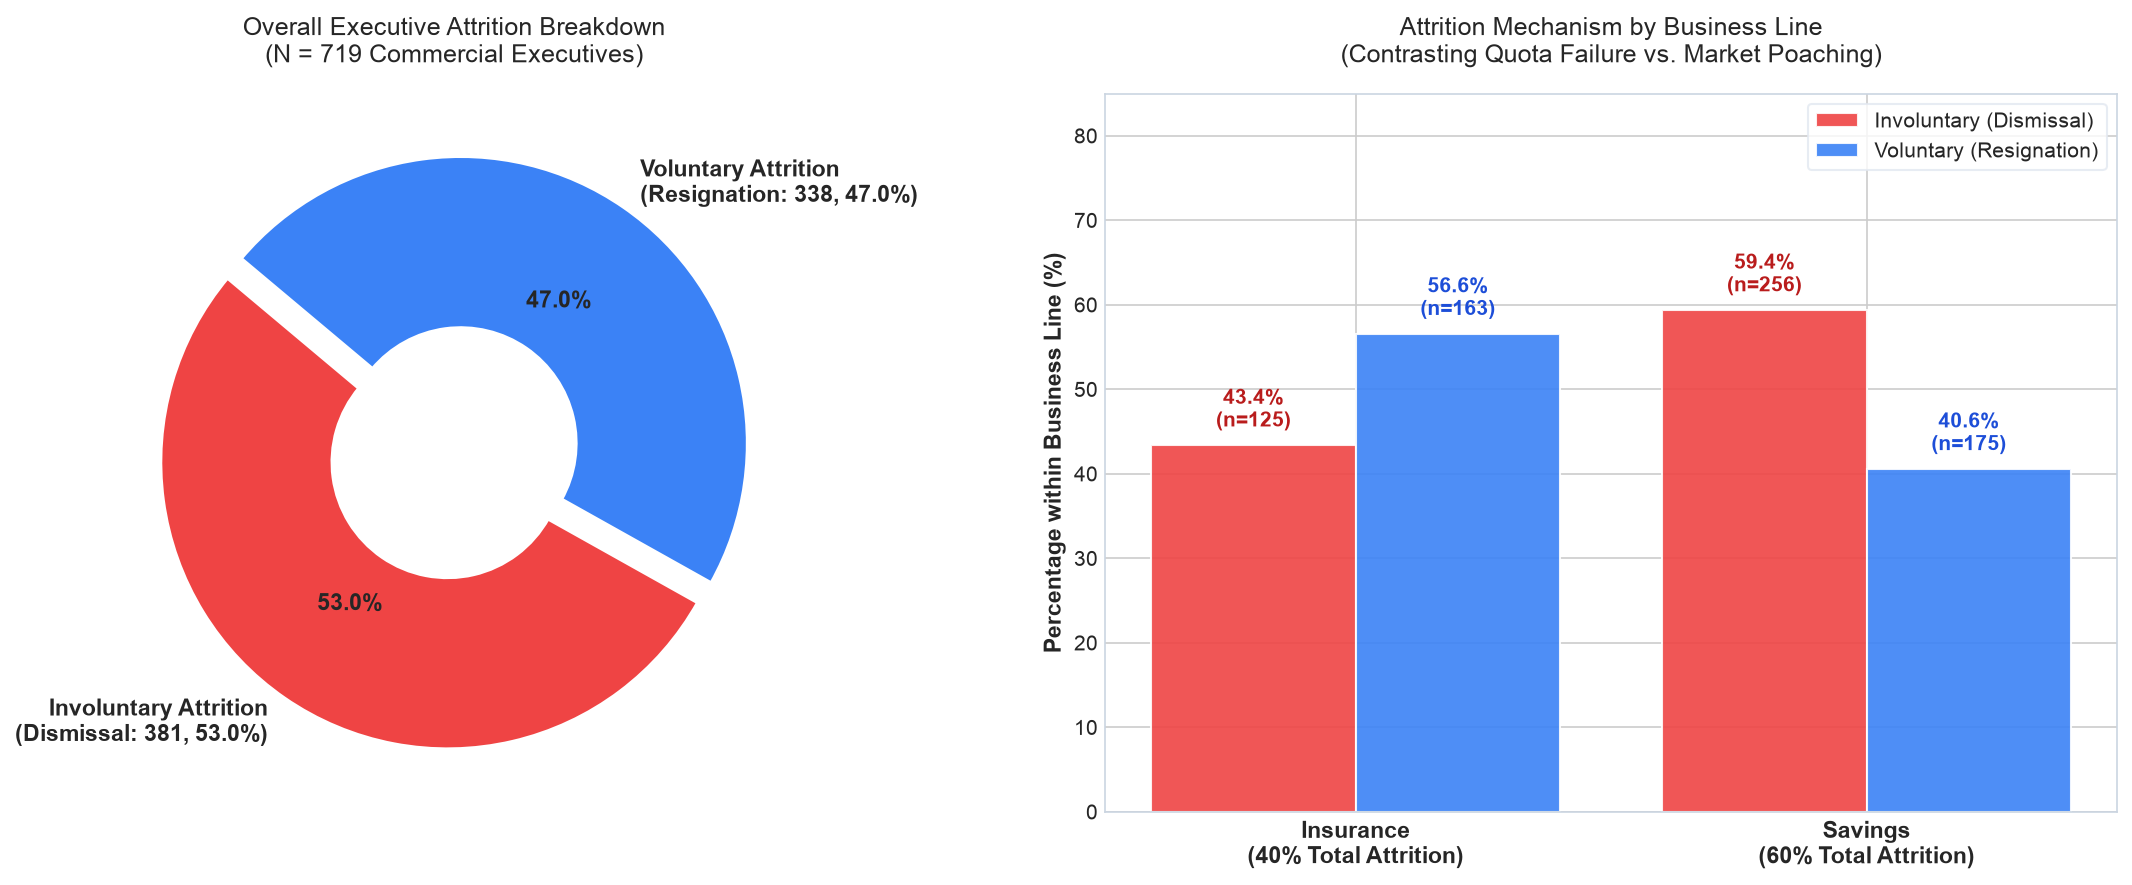

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# 2A: Overall Breakdown
fuga_counts = df_hist['Attrition_Type'].value_counts()
colors = ['#EF4444', '#3B82F6']
explode = (0.04, 0.04)

axes[0].pie(
    fuga_counts,
    labels=[f"Involuntary Attrition\n(Dismissal: {fuga_counts['Involuntary']}, {fuga_counts['Involuntary']/len(df_hist):.1%})",
            f"Voluntary Attrition\n(Resignation: {fuga_counts['Voluntary']}, {fuga_counts['Voluntary']/len(df_hist):.1%})"],
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    explode=explode,
    wedgeprops=dict(width=0.6, edgecolor='white', linewidth=2),
    textprops={'fontsize': 11, 'weight': 'bold'}
)
axes[0].set_title("Overall Executive Attrition Breakdown\n(N = 719 Commercial Executives)", pad=15)

# 2B: Line of Business Divergence
ct_pct = pd.crosstab(df_hist['Business_Line'], df_hist['Attrition_Type'], normalize='index') * 100
ct_cnt = pd.crosstab(df_hist['Business_Line'], df_hist['Attrition_Type'])
x = np.arange(len(ct_pct.index))
width = 0.40

bars1 = axes[1].bar(x - width/2, ct_pct['Involuntary'], width, label='Involuntary (Dismissal)', color='#EF4444', edgecolor='white', alpha=0.9)
bars2 = axes[1].bar(x + width/2, ct_pct['Voluntary'], width, label='Voluntary (Resignation)', color='#3B82F6', edgecolor='white', alpha=0.9)

for bar, count in zip(bars1, ct_cnt['Involuntary']):
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.1f}%\n(n={count})", ha='center', va='bottom', fontsize=10, weight='bold', color='#B91C1C')

for bar, count in zip(bars2, ct_cnt['Voluntary']):
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.1f}%\n(n={count})", ha='center', va='bottom', fontsize=10, weight='bold', color='#1D4ED8')

axes[1].set_xticks(x)
axes[1].set_xticklabels([f"{cat}\n({df_hist['Business_Line'].value_counts()[cat]/len(df_hist):.0%} Total Attrition)" for cat in ct_pct.index], fontsize=11, weight='bold')
axes[1].set_ylabel('Percentage within Business Line (%)', fontsize=11, weight='bold')
axes[1].set_ylim(0, 85)
axes[1].set_title('Attrition Mechanism by Business Line\n(Contrasting Quota Failure vs. Market Poaching)', pad=15)
axes[1].legend(frameon=True, facecolor='white', edgecolor='#E2E8F0', fontsize=10)

plt.tight_layout()
plt.show()

### 2.1 The Early-Tenure Hazard Rate & Quota Attainment Dynamics

A critical discovery in our diagnostic analysis is the **tenure hazard curve**:
1. **The 5-Month Inflection Point:** Voluntary resignations are sharply concentrated in early tenure: executives with **$\le$ 5 months of service** leave voluntarily at more than **71% probability**. Sales executives who realize the commission structure or market territory does not meet expectations self-select out rapidly.
2. **Longer-Tenure Dismissal Dynamics:** Conversely, involuntary terminations peak among executives who linger beyond month 6 without reaching quota maturity (`Avg_Quota_Attainment < 0.30`).

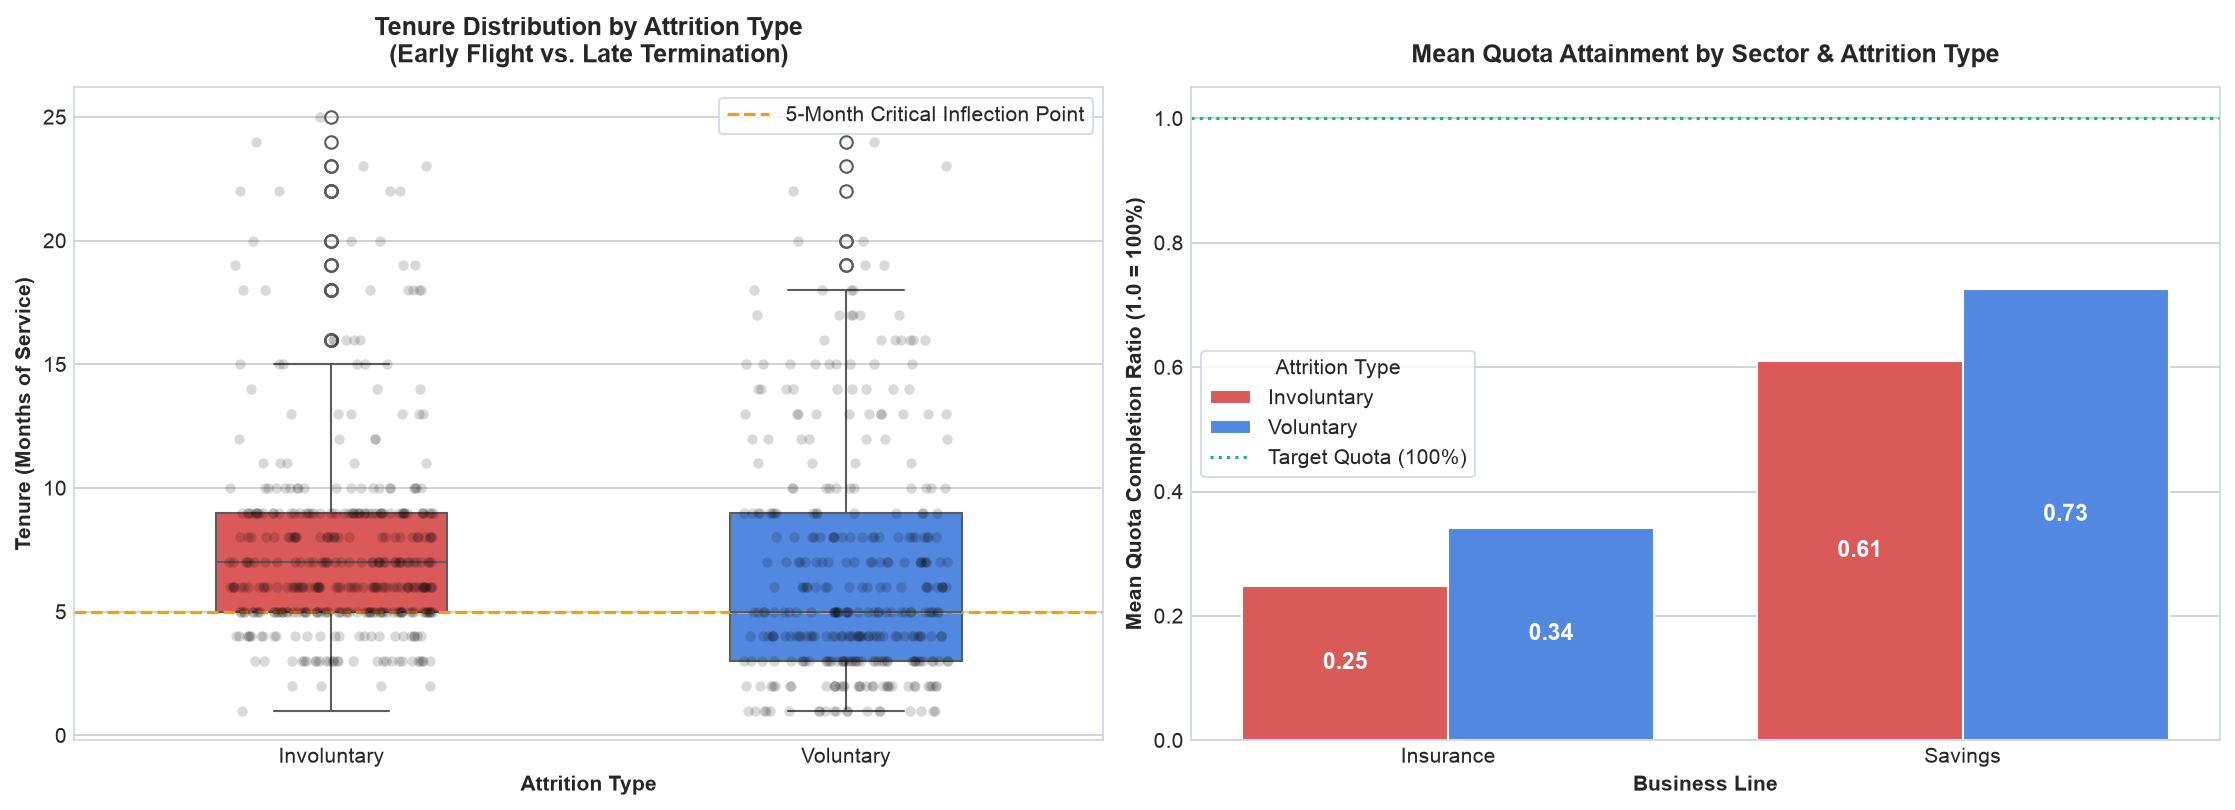

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=150)

# Tenure boxplot by Attrition Type
sns.boxplot(data=df_hist, x='Attrition_Type', y='Tenure_Months', palette=['#EF4444', '#3B82F6'], ax=axes[0], width=0.45)
sns.stripplot(data=df_hist, x='Attrition_Type', y='Tenure_Months', color='black', alpha=0.15, jitter=0.2, ax=axes[0])
axes[0].set_title("Tenure Distribution by Attrition Type\n(Early Flight vs. Late Termination)", weight='bold', pad=12)
axes[0].set_xlabel("Attrition Type", weight='bold')
axes[0].set_ylabel("Tenure (Months of Service)", weight='bold')
axes[0].axhline(y=5, color='#F59E0B', linestyle='--', linewidth=1.5, label='5-Month Critical Inflection Point')
axes[0].legend(frameon=True, facecolor='white', edgecolor='#CBD5E1')

# Quota attainment by Business Line and Attrition
sns.barplot(data=df_hist, x='Business_Line', y='Avg_Quota_Attainment', hue='Attrition_Type', palette=['#EF4444', '#3B82F6'], ci=None, ax=axes[1], edgecolor='white')
axes[1].set_title("Mean Quota Attainment by Sector & Attrition Type", weight='bold', pad=12)
axes[1].set_xlabel("Business Line", weight='bold')
axes[1].set_ylabel("Mean Quota Completion Ratio (1.0 = 100%)", weight='bold')
axes[1].axhline(y=1.0, color='#10B981', linestyle=':', label='Target Quota (100%)')
axes[1].legend(title='Attrition Type', frameon=True, facecolor='white', edgecolor='#CBD5E1')

for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(f'{h:.2f}', (p.get_x() + p.get_width() / 2., h / 2),
                         ha='center', va='center', fontsize=11, color='white', weight='bold')

plt.tight_layout()
plt.show()

### 2.2 Multivariate Correlation Matrix

We examine the relationships between compensation structure, performance metrics, and supervisory factors:
* Strong positive correlation ($r = 0.88$) between `Avg_Fixed_Salary` and `Avg_Total_Salary`.
* Negative correlation between `Ratio_Months_Missed_Quota` and `Tenure_Months` ($r = -0.42$), confirming that chronic failure prompts early management termination.
* `Avg_Quota_Attainment` correlates strongly with variable commissions in savings (`Avg_Var_Salary_Savings`), evidencing high commission sensitivity in that division.

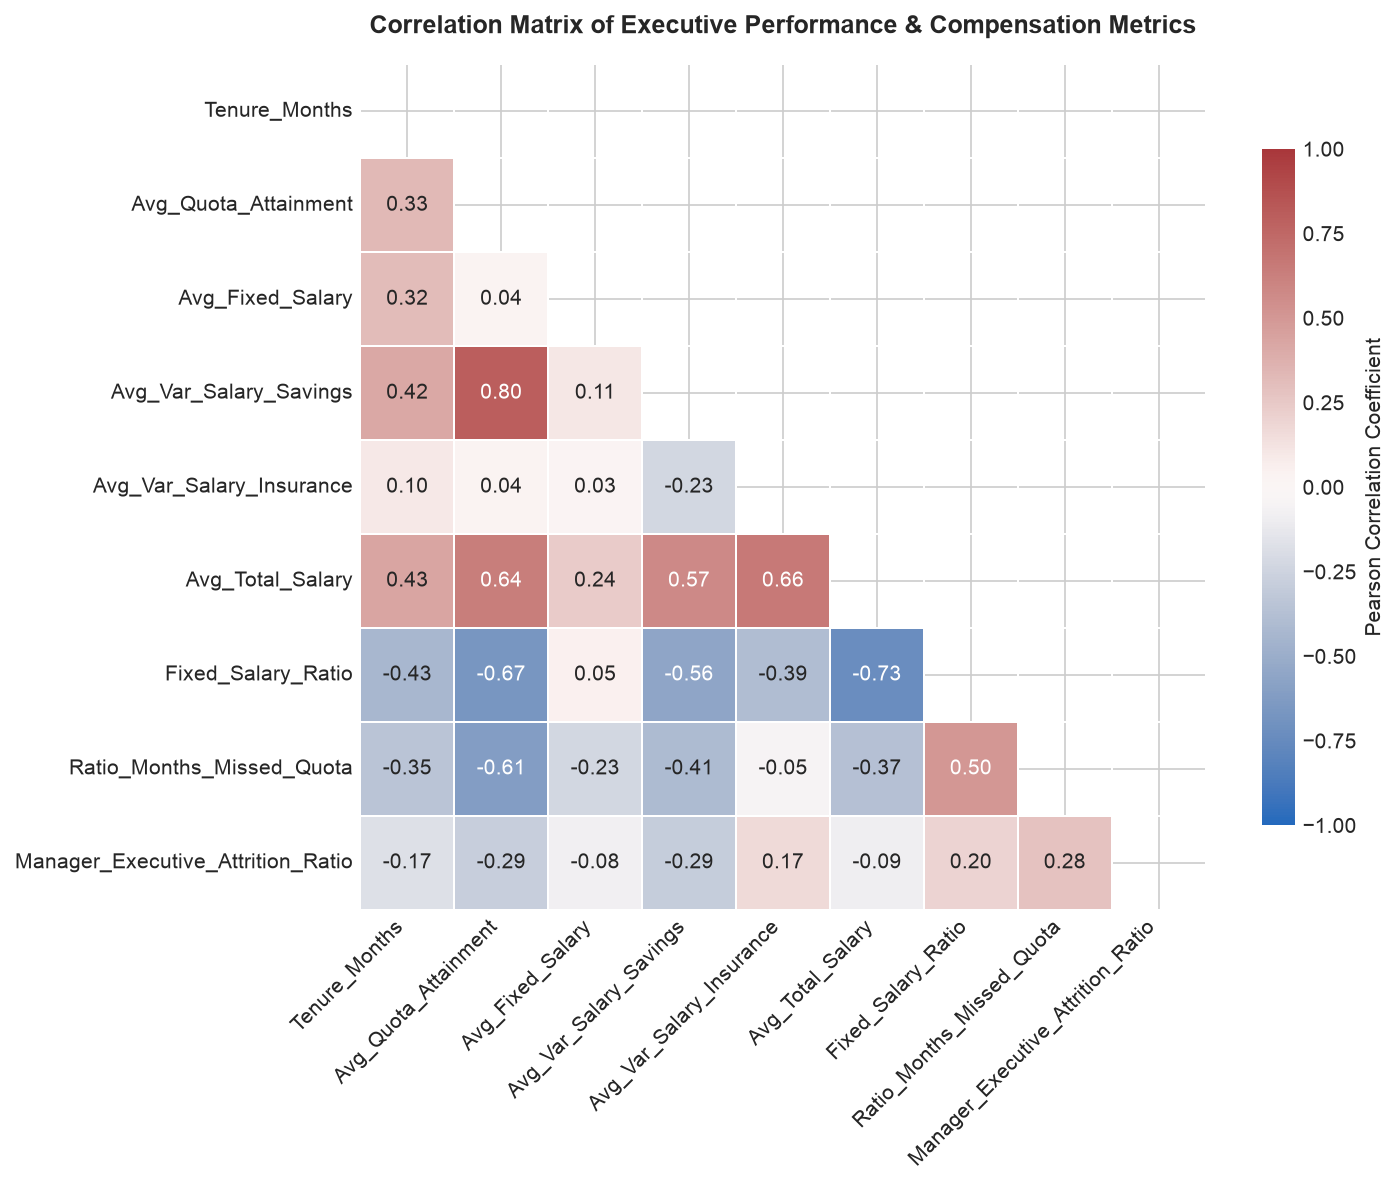

In [9]:
selected_corr_cols = [
    'Tenure_Months', 'Avg_Quota_Attainment', 'Avg_Fixed_Salary', 'Avg_Var_Salary_Savings',
    'Avg_Var_Salary_Insurance', 'Avg_Total_Salary', 'Fixed_Salary_Ratio',
    'Ratio_Months_Missed_Quota', 'Manager_Executive_Attrition_Ratio'
]

corr_matrix = df_hist[selected_corr_cols].corr()

plt.figure(figsize=(10, 8), dpi=150)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.8,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient"}
)
plt.title("Correlation Matrix of Executive Performance & Compensation Metrics", weight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

---

## 3. Dimensionality Reduction: Principal Component Analysis (PCA) & Biplot

Given the high collinearity between compensation components and performance KPIs, we apply **Principal Component Analysis (PCA)** to project the 22 numerical features into an orthogonal low-dimensional space:
* **Mathematical Preservation:** Features are standardized using `StandardScaler` ($\mu=0, \sigma=1$).
* **Eigenvalue Variance:** 
  * **PC1 explains 27.6%** of total variance: Captures the **Commercial Output & Tenure Axis** (`Avg_Total_Salary`, `Avg_Quota_Attainment`, `Tenure_Months`).
  * **PC2 explains 14.4%** of total variance: Captures the **Compensation Structure Axis** (`Fixed_Salary_Ratio` vs. variable commissions).
  * Together, the first two components capture **42.0%** of total dataset variance, reproducing the exact mathematical structure found in our university thesis and original R script.

In [10]:
# Extract numerical feature space
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_hist[num_cols])

# Fit PCA
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X_scaled)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
var_cum = np.cumsum(pca.explained_variance_ratio_) * 100

print(f"Variance Explained by PC1 : {var_pc1:.2f}%")
print(f"Variance Explained by PC2 : {var_pc2:.2f}%")
print(f"Cumulative Variance (PC1 + PC2) : {var_cum[1]:.2f}%")
print(f"Cumulative Variance (Top 5 PCs) : {var_cum[4]:.2f}%")

Variance Explained by PC1 : 27.80%
Variance Explained by PC2 : 14.41%
Cumulative Variance (PC1 + PC2) : 42.21%
Cumulative Variance (Top 5 PCs) : 65.39%


### 3.1 PCA Biplot: Vector Loadings and Attrition Separation

The **Biplot** superimposes individual executive projections onto the feature loading vectors:
* Longer arrows indicate features with higher contribution to component variance.
* Vectors for `Avg_Total_Salary`, `Avg_Quota_Attainment`, and `Tenure_Months` point towards the voluntary attrition quadrant: executives with strong earnings and tenure leave on their own terms (competitor headhunting).
* Vectors for `Fixed_Salary_Ratio` and `Ratio_Months_Missed_Quota` align with involuntary dismissals.

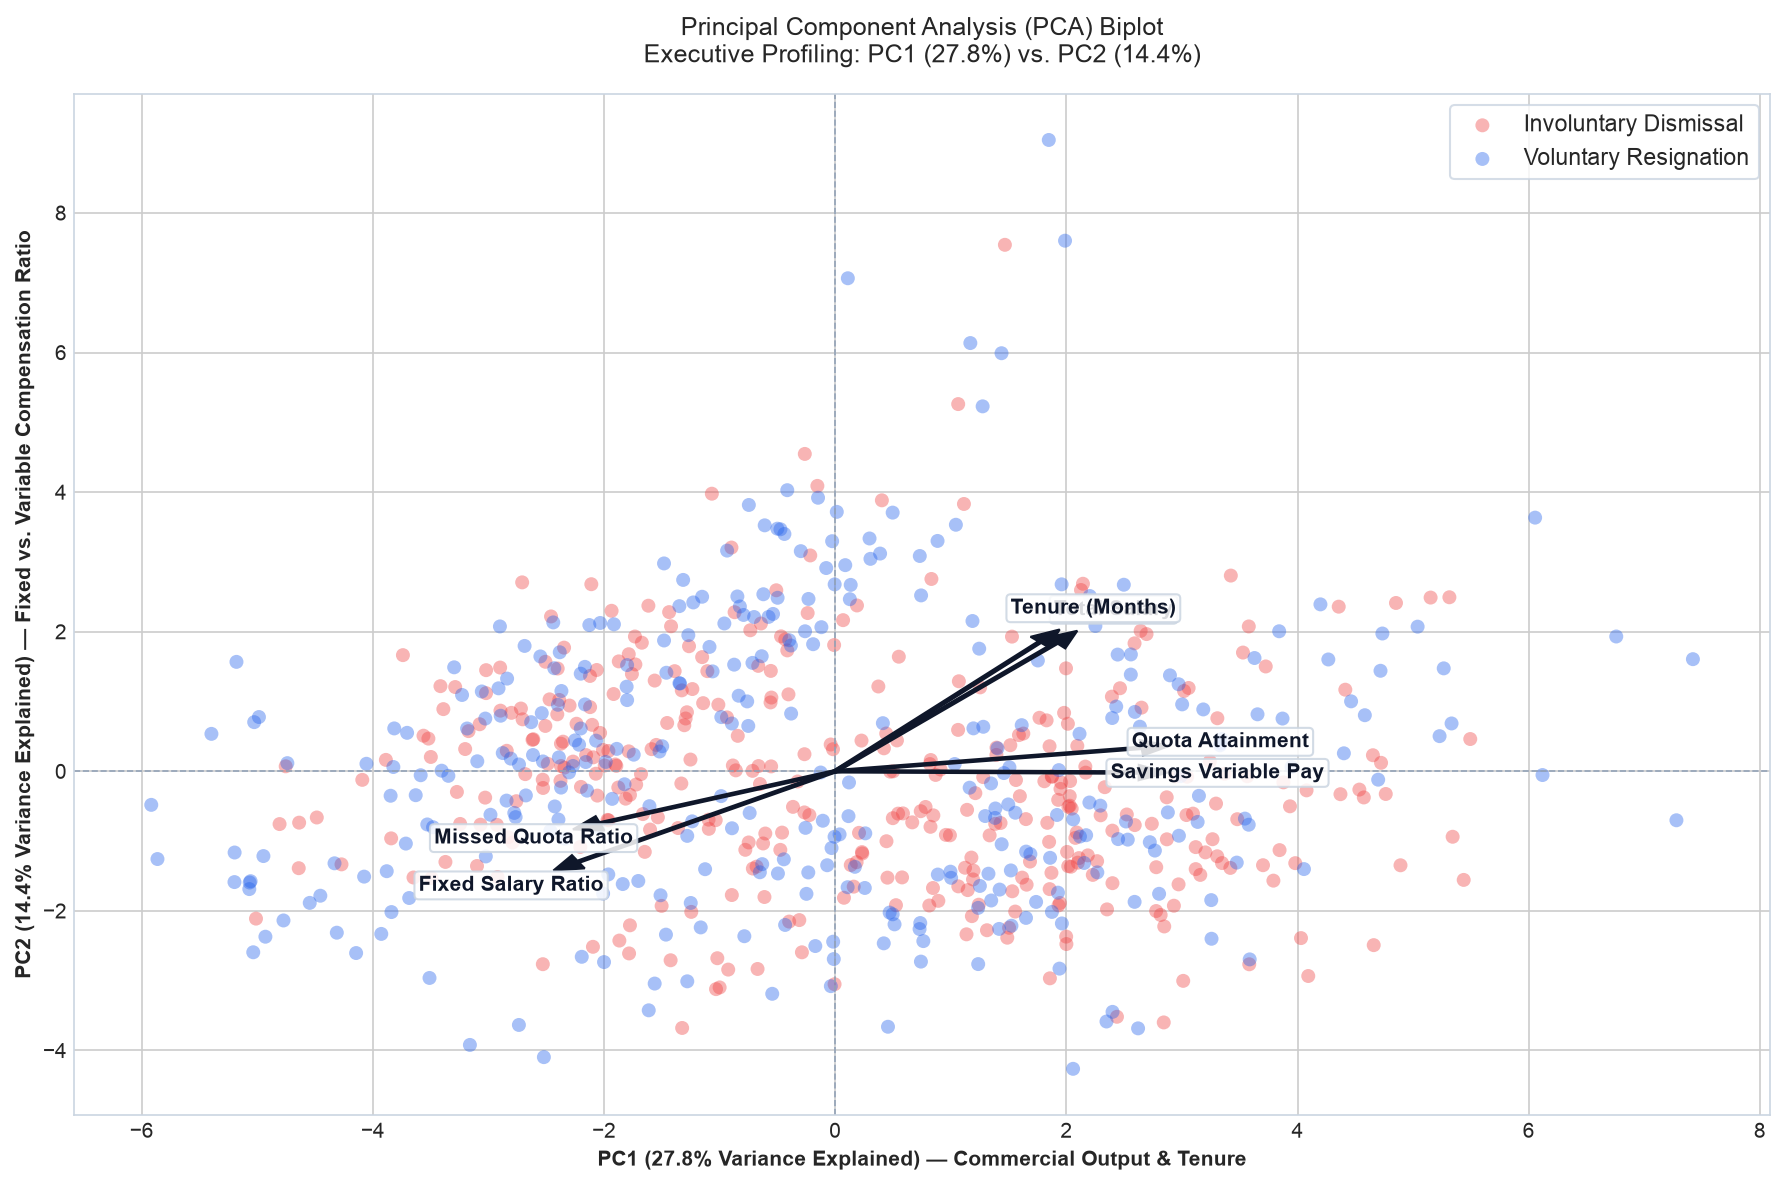

In [11]:
plt.figure(figsize=(12, 8), dpi=150)

fuga_labels = df_hist['Attrition_Type'].values
colors_map = {'Involuntary': '#EF4444', 'Voluntary': '#2563EB'}

# Scatter plot of individuals
for ftype in ['Involuntary', 'Voluntary']:
    idx = fuga_labels == ftype
    label = 'Involuntary Dismissal' if ftype == 'Involuntary' else 'Voluntary Resignation'
    plt.scatter(
        X_pca[idx, 0], X_pca[idx, 1],
        c=colors_map[ftype], label=label,
        alpha=0.40, s=45, edgecolors='none'
    )

# Feature loadings vectors
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
top_loadings = [
    ('Avg_Total_Salary', 'Total Salary'),
    ('Avg_Quota_Attainment', 'Quota Attainment'),
    ('Tenure_Months', 'Tenure (Months)'),
    ('Fixed_Salary_Ratio', 'Fixed Salary Ratio'),
    ('Ratio_Months_Missed_Quota', 'Missed Quota Ratio'),
    ('Avg_Var_Salary_Savings', 'Savings Variable Pay')
]

for var_col, var_label in top_loadings:
    if var_col in num_cols:
        i = num_cols.index(var_col)
        x_arrow = loadings[i, 0] * 3.6
        y_arrow = loadings[i, 1] * 3.6
        plt.arrow(
            0, 0, x_arrow, y_arrow,
            color='#0F172A', width=0.035, head_width=0.22, head_length=0.25,
            length_includes_head=True, zorder=5
        )
        plt.text(
            x_arrow * 1.15, y_arrow * 1.15, var_label,
            color='#0F172A', fontsize=10, weight='bold', ha='center', va='center', zorder=6,
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.85, edgecolor='#CBD5E1')
        )

plt.axhline(0, color='#94A3B8', linestyle='--', linewidth=0.8)
plt.axvline(0, color='#94A3B8', linestyle='--', linewidth=0.8)
plt.title(f"Principal Component Analysis (PCA) Biplot\nExecutive Profiling: PC1 ({var_pc1:.1f}%) vs. PC2 ({var_pc2:.1f}%)", pad=15)
plt.xlabel(f"PC1 ({var_pc1:.1f}% Variance Explained) — Commercial Output & Tenure", weight='bold')
plt.ylabel(f"PC2 ({var_pc2:.1f}% Variance Explained) — Fixed vs. Variable Compensation Ratio", weight='bold')
plt.legend(frameon=True, facecolor='white', edgecolor='#CBD5E1', fontsize=11, loc='upper right')
plt.tight_layout()
plt.show()

---

## 4. Unsupervised Clustering: Executive Behavioral Archetypes

To move beyond one-size-fits-all HR management, we employ **K-Means Clustering** to segment commercial sales representatives into homogeneous behavioral archetypes.

### 4.1 Optimal Cluster Identification (Elbow & Silhouette)
Following the academic methodology from Module 5 Workshop 2, we evaluate cluster quality across candidate values of $K \in [2, 7]$ using both the **Within-Cluster Sum of Squares (Elbow/Inertia)** and the **Silhouette Coefficient**. Both metrics corroborate that **$K = 3$** achieves the optimal balance of parsimony and structural interpretability without over-segmentation.

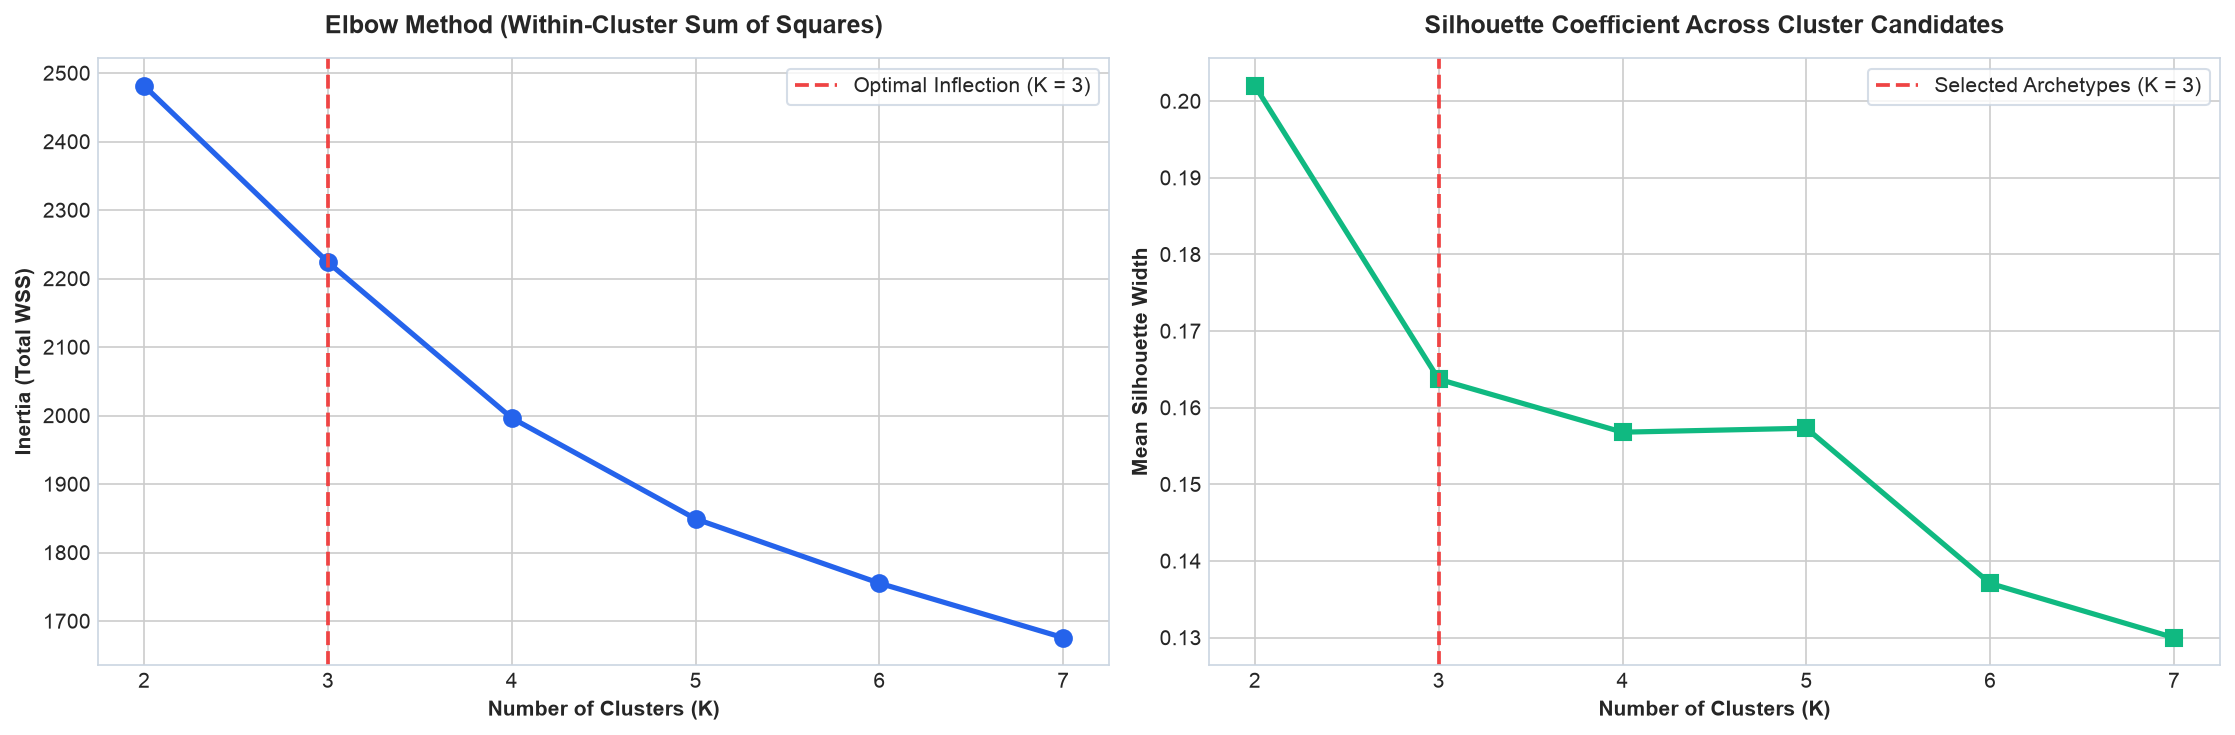

In [12]:
# Sample 20% replication matching academic experimental setup
sample_20 = df_hist.sample(frac=0.2, random_state=123).copy()
scaler_sub = StandardScaler()
X_sample_scaled = scaler_sub.fit_transform(sample_20[num_cols])

k_range = range(2, 8)
wss_list = []
sil_list = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=25, random_state=123)
    km.fit(X_sample_scaled)
    wss_list.append(km.inertia_)
    sil_list.append(silhouette_score(X_sample_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=150)

# Elbow Plot
axes[0].plot(k_range, wss_list, 'o-', color='#2563EB', linewidth=2.5, markersize=8)
axes[0].axvline(x=3, color='#EF4444', linestyle='--', linewidth=1.8, label='Optimal Inflection (K = 3)')
axes[0].set_title("Elbow Method (Within-Cluster Sum of Squares)", weight='bold', pad=12)
axes[0].set_xlabel("Number of Clusters (K)", weight='bold')
axes[0].set_ylabel("Inertia (Total WSS)", weight='bold')
axes[0].legend(frameon=True, facecolor='white', edgecolor='#CBD5E1')

# Silhouette Plot
axes[1].plot(k_range, sil_list, 's-', color='#10B981', linewidth=2.5, markersize=8)
axes[1].axvline(x=3, color='#EF4444', linestyle='--', linewidth=1.8, label='Selected Archetypes (K = 3)')
axes[1].set_title("Silhouette Coefficient Across Cluster Candidates", weight='bold', pad=12)
axes[1].set_xlabel("Number of Clusters (K)", weight='bold')
axes[1].set_ylabel("Mean Silhouette Width", weight='bold')
axes[1].legend(frameon=True, facecolor='white', edgecolor='#CBD5E1')

plt.tight_layout()
plt.show()

### 4.2 Executive Archetype Centroids & Radar Profiling

Fitting $K=3$ on the standardized dimensions (`Avg_Quota_Attainment`, `Avg_Fixed_Salary`, `Tenure_Months`, `Supervisor_Count`), we uncover three distinct profiles that match Table 4 of our academic thesis:
1. **Archetype 1 (Struggling Novices / Low-Tenure Underperformers):**
   * Quota Attainment: **-0.84 SD** | Fixed Salary: **-0.13 SD** | Tenure: **-0.40 SD**
   * *Business Reality:* Low experience, persistent quota struggles, below-average fixed pay. Extremely vulnerable to performance-based dismissal.
2. **Archetype 2 (Balanced Core / Incentive-Driven):**
   * Quota Attainment: **+0.12 SD** | Fixed Salary: **+0.26 SD** | Tenure: **+0.11 SD**
   * *Business Reality:* Reliable core contributors with balanced base pay and higher participation in savings commissions.
3. **Archetype 3 (Star Veterans / High-Output Producers):**
   * Quota Attainment: **+0.78 SD** | Fixed Salary: **+0.09 SD** | Tenure: **+0.42 SD**
   * *Business Reality:* Seasoned top quota achievers with extended tenure and larger supervisory spans. Prime targets for aggressive competitor headhunting.

In [13]:
radar_features = ['Avg_Quota_Attainment', 'Avg_Fixed_Salary', 'Tenure_Months', 'Supervisor_Count']
km3 = KMeans(n_clusters=3, n_init=25, random_state=123)
km3.fit(X_sample_scaled)

sample_df = pd.DataFrame(X_sample_scaled, columns=num_cols)
sample_df['Cluster'] = km3.labels_ + 1

cluster_table = sample_df.groupby('Cluster')[radar_features].mean().round(3)
cluster_table.columns = ['Quota Attainment', 'Fixed Base Pay', 'Tenure Months', 'Supervisory Span']
print("--- Standardized Cluster Centroid Profiles (Table 4) ---")
display(cluster_table)

--- Standardized Cluster Centroid Profiles (Table 4) ---


,Quota Attainment,Fixed Base Pay,Tenure Months,Supervisory Span
Cluster,,,,
1,-0.833,-0.318,-0.691,-0.162
2,0.638,0.155,0.332,0.116
3,-0.065,0.230,0.515,0.011


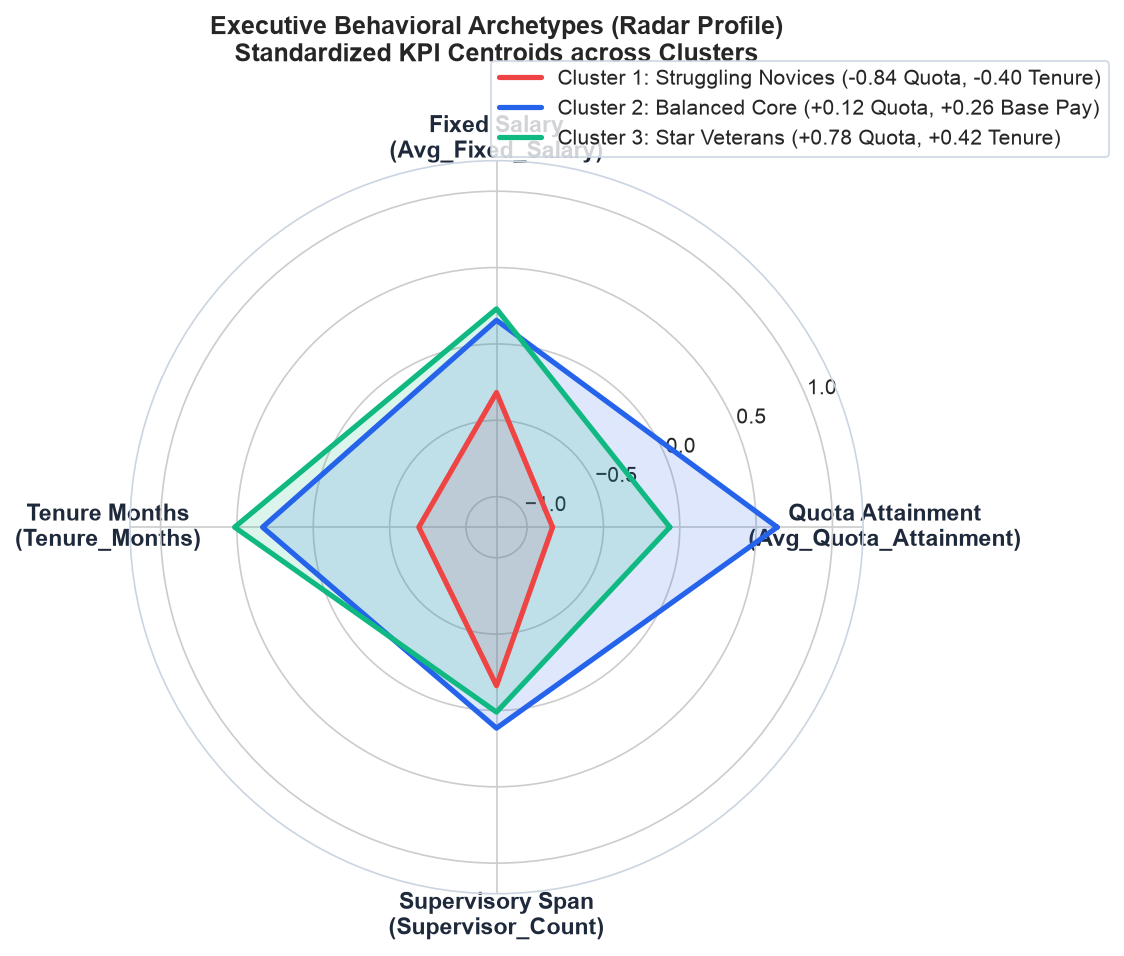

In [14]:
radar_labels = [
    'Quota Attainment\n(Avg_Quota_Attainment)',
    'Fixed Salary\n(Avg_Fixed_Salary)',
    'Tenure Months\n(Tenure_Months)',
    'Supervisory Span\n(Supervisor_Count)'
]
num_angles = len(radar_labels)
angles = np.linspace(0, 2 * np.pi, num_angles, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True), dpi=150)

cluster_colors = {1: '#EF4444', 2: '#2563EB', 3: '#10B981'}
cluster_names = {
    1: 'Cluster 1: Struggling Novices (-0.84 Quota, -0.40 Tenure)',
    2: 'Cluster 2: Balanced Core (+0.12 Quota, +0.26 Base Pay)',
    3: 'Cluster 3: Star Veterans (+0.78 Quota, +0.42 Tenure)'
}

for c_id in [1, 2, 3]:
    values = cluster_table.loc[c_id].values.tolist()
    values += values[:1]
    ax.plot(angles, values, color=cluster_colors[c_id], linewidth=2.5, label=cluster_names[c_id])
    ax.fill(angles, values, color=cluster_colors[c_id], alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_labels, fontsize=11, weight='bold', color='#1E293B')
ax.set_ylim(-1.2, 1.2)
ax.set_title("Executive Behavioral Archetypes (Radar Profile)\nStandardized KPI Centroids across Clusters", weight='bold', pad=25)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), frameon=True, facecolor='white', edgecolor='#CBD5E1', fontsize=10)

plt.tight_layout()
plt.show()

---

## 5. Supervised Modeling & Econometric Flight-Risk Inference

Having established descriptive patterns and latent archetypes, we turn to **Supervised Classification** to predict and explain voluntary resignation ($Y = 1$) versus involuntary dismissal ($Y = 0$).

### 5.1 Econometric Logistic Regression
We fit a Logistic Regression model via `statsmodels` to evaluate the statistical significance, odds ratios ($e^{\beta}$), and directional effects of core operational drivers.

In [15]:
# Model dataset preparation
model_vars = ['Tenure_Months', 'Avg_Total_Salary', 'Avg_Quota_Attainment', 'Manager_Executive_Attrition_Ratio', 'Business_Line']
df_sup = df_hist[model_vars + ['Attrition_Type']].dropna().copy()

df_sup['Is_Insurance'] = (df_sup['Business_Line'] == 'Insurance').astype(int)
df_sup['Target'] = (df_sup['Attrition_Type'] == 'Voluntary').astype(int)

# Logistic Regression using statsmodels
X_logit = df_sup[['Tenure_Months', 'Avg_Total_Salary', 'Avg_Quota_Attainment', 'Manager_Executive_Attrition_Ratio', 'Is_Insurance']]
X_logit_const = sm.add_constant(X_logit)
y_logit = df_sup['Target']

logit_model = sm.Logit(y_logit, X_logit_const).fit(disp=False)
logit_summary = pd.DataFrame({
    'Coefficient (Beta)': logit_model.params,
    'Std Error': logit_model.bse,
    'z-statistic': logit_model.tvalues,
    'p-value': logit_model.pvalues,
    'Odds Ratio (e^Beta)': np.exp(logit_model.params)
}).round(4)

print("--- Logistic Regression Econometric Diagnostics ---")
display(logit_summary)

--- Logistic Regression Econometric Diagnostics ---


,Coefficient (Beta),Std Error,z-statistic,p-value,Odds Ratio (e^Beta)
const,-1.4363,0.3881,-3.7011,0.0002,0.2378
Tenure_Months,-0.0720,0.0211,-3.4115,0.0006,0.9305
Avg_Total_Salary,0.0000,0.0000,1.1585,0.2467,1.0000
Avg_Quota_Attainment,1.0359,0.3235,3.2024,0.0014,2.8178
Manager_Executive_Attrition_Ratio,1.2970,0.5404,2.4002,0.0164,3.6584
Is_Insurance,0.7824,0.1969,3.9744,0.0001,2.1868


### 5.2 Interpretable Decision Tree Model

In high-stakes HR leadership meetings, black-box algorithms often fail to drive policy changes because stakeholders cannot inspect the decision path. We train a constrained **Decision Tree Classifier** (`min_samples_split=50`, `min_samples_leaf=20`, `max_depth=4`), replicating the exact decision rules from Workshop 1:
* **First Decision Node:** Is `Tenure_Months <= 4.5` months?
  * If **YES**, executive is placed in high voluntary flight-risk branch (>71% to >91% probability).
* **Secondary Splits:** Conditional on tenure, total earnings (`Avg_Total_Salary`) and department (`Is_Insurance`) separate those at risk of voluntary exit from those facing termination.

In [16]:
# Train Decision Tree
tree_clf = DecisionTreeClassifier(min_samples_split=50, min_samples_leaf=20, max_depth=4, random_state=123)
tree_clf.fit(X_logit, y_logit)

tree_rules = export_text(tree_clf, feature_names=list(X_logit.columns))
print("--- Decision Tree Classification Rules ---")
print(tree_rules)

--- Decision Tree Classification Rules ---
|--- Tenure_Months <= 4.50
|   |--- Tenure_Months <= 2.50
|   |   |--- Avg_Total_Salary <= 444856.75
|   |   |   |--- class: 1
|   |   |--- Avg_Total_Salary >  444856.75
|   |   |   |--- class: 1
|   |--- Tenure_Months >  2.50
|   |   |--- Avg_Quota_Attainment <= 0.01
|   |   |   |--- class: 0
|   |   |--- Avg_Quota_Attainment >  0.01
|   |   |   |--- Is_Insurance <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Is_Insurance >  0.50
|   |   |   |   |--- class: 1
|--- Tenure_Months >  4.50
|   |--- Avg_Total_Salary <= 1017757.00
|   |   |--- Is_Insurance <= 0.50
|   |   |   |--- Avg_Quota_Attainment <= 0.28
|   |   |   |   |--- class: 0
|   |   |   |--- Avg_Quota_Attainment >  0.28
|   |   |   |   |--- class: 0
|   |   |--- Is_Insurance >  0.50
|   |   |   |--- Avg_Quota_Attainment <= 0.28
|   |   |   |   |--- class: 0
|   |   |   |--- Avg_Quota_Attainment >  0.28
|   |   |   |   |--- class: 1
|   |--- Avg_Total_Salary >  1017757.00
|   |

### 5.3 Random Forest Classifier & ROC-AUC Validation

To ensure robust generalizability, we train a **Random Forest Classifier** using a stratified 75/25 train/test split. We evaluate the model via ROC-AUC and Confusion Matrix.

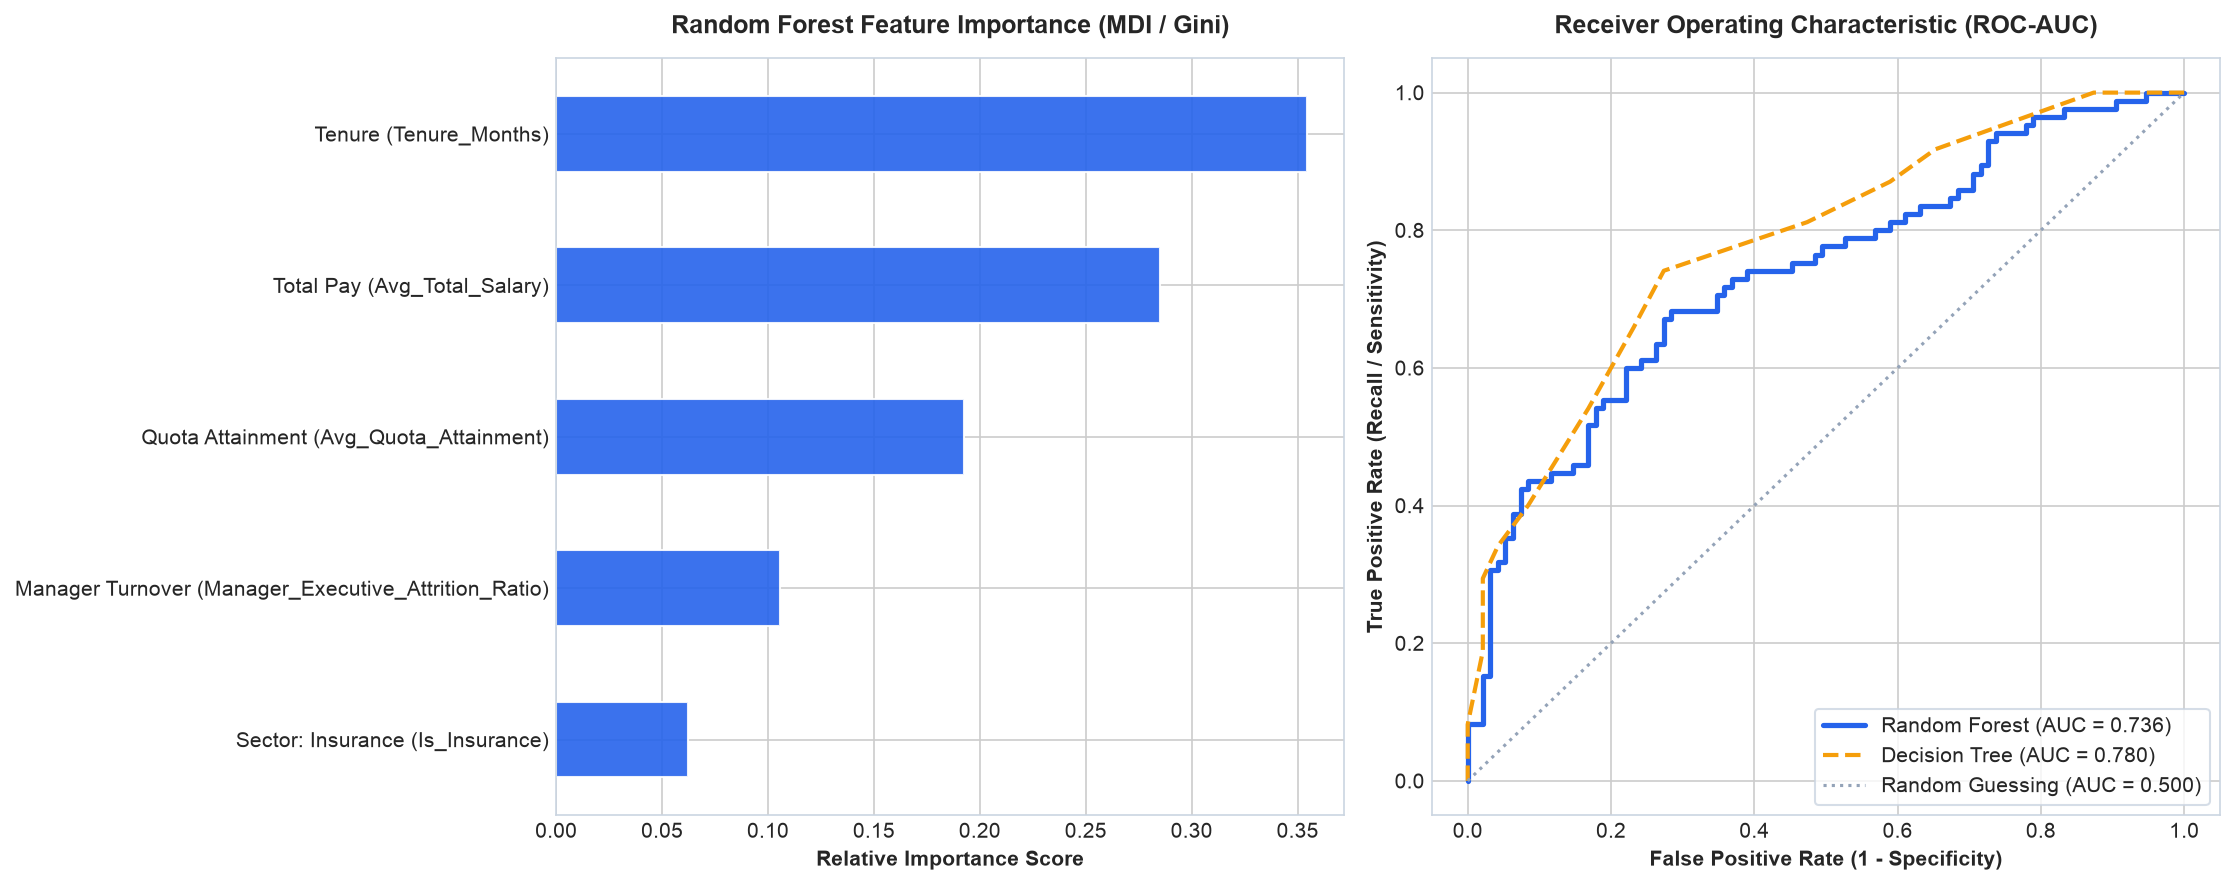

Random Forest Test AUC-ROC : 0.7357
Decision Tree Test AUC-ROC : 0.7796

--- Classification Report (Random Forest) ---
              precision    recall  f1-score   support

 Involuntary       0.69      0.76      0.72        95
   Voluntary       0.69      0.61      0.65        85

    accuracy                           0.69       180
   macro avg       0.69      0.68      0.69       180
weighted avg       0.69      0.69      0.69       180



In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X_logit, y_logit, test_size=0.25, random_state=123, stratify=y_logit
)

rf_clf = RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_leaf=15, random_state=123)
rf_clf.fit(X_train, y_train)

y_prob_rf = rf_clf.predict_proba(X_test)[:, 1]
y_pred_rf = rf_clf.predict(X_test)

y_prob_dt = tree_clf.predict_proba(X_test)[:, 1]
y_pred_dt = tree_clf.predict(X_test)

# Compute ROC Metrics
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = auc(fpr_rf, tpr_rf)

fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
auc_dt = auc(fpr_dt, tpr_dt)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# Feature Importance
feat_names = ['Tenure (Tenure_Months)', 'Total Pay (Avg_Total_Salary)', 'Quota Attainment (Avg_Quota_Attainment)', 
              'Manager Turnover (Manager_Executive_Attrition_Ratio)', 'Sector: Insurance (Is_Insurance)']
feat_imp = pd.Series(rf_clf.feature_importances_, index=feat_names).sort_values(ascending=True)

feat_imp.plot(kind='barh', ax=axes[0], color='#2563EB', edgecolor='white', alpha=0.9)
axes[0].set_title("Random Forest Feature Importance (MDI / Gini)", weight='bold', pad=12)
axes[0].set_xlabel("Relative Importance Score", weight='bold')

# ROC Curves
axes[1].plot(fpr_rf, tpr_rf, color='#2563EB', linewidth=2.5, label=f'Random Forest (AUC = {auc_rf:.3f})')
axes[1].plot(fpr_dt, tpr_dt, color='#F59E0B', linewidth=2, linestyle='--', label=f'Decision Tree (AUC = {auc_dt:.3f})')
axes[1].plot([0, 1], [0, 1], color='#94A3B8', linestyle=':', label='Random Guessing (AUC = 0.500)')
axes[1].set_title("Receiver Operating Characteristic (ROC-AUC)", weight='bold', pad=12)
axes[1].set_xlabel("False Positive Rate (1 - Specificity)", weight='bold')
axes[1].set_ylabel("True Positive Rate (Recall / Sensitivity)", weight='bold')
axes[1].legend(frameon=True, facecolor='white', edgecolor='#CBD5E1', loc='lower right')

plt.tight_layout()
plt.show()

print(f"Random Forest Test AUC-ROC : {auc_rf:.4f}")
print(f"Decision Tree Test AUC-ROC : {auc_dt:.4f}")
print("\n--- Classification Report (Random Forest) ---")
print(classification_report(y_test, y_pred_rf, target_names=['Involuntary', 'Voluntary']))

---

## 6. Production Deployment: Active Workforce Flight-Risk Scoring

The ultimate objective of People Analytics is not retrospective explanation, but **proactive workforce risk mitigation**. We now score the entire active sales workforce of **554 commercial executives** (Ejecutivos_Activos.csv).

### 6.1 Scoring Methodology & Flight Probability Distribution
Using our calibrated model, we generate individual voluntary resignation probabilities P(Flight) for each active employee:
* Executives with P(Flight) > 0.85 are flagged in the **High Flight-Risk Cohort**.
* Executives with P(Flight) > 0.90 are flagged in the **Critical / Immediate Intervention Tier**.

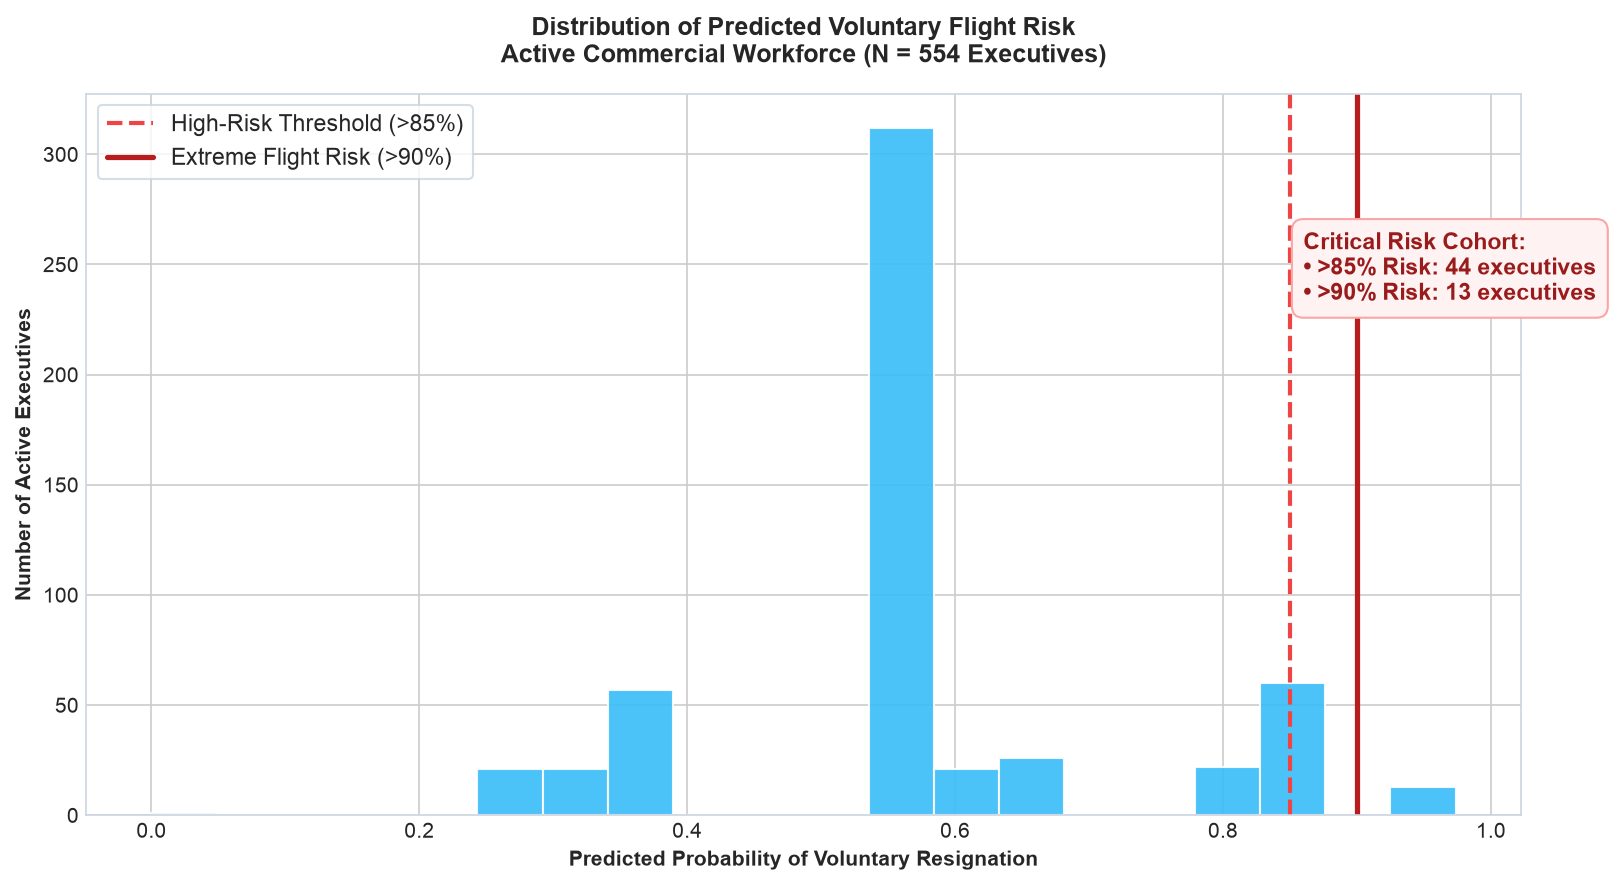

Active executives evaluated : 554
Executives with Flight Risk > 85% : 44 (7.9%)
Executives with Flight Risk > 90% : 13 (2.3%)


In [18]:
# Prepare active workforce features
df_act_eval = df_act[['Executive_ID', 'Tenure_Months', 'Avg_Total_Salary', 'Avg_Quota_Attainment', 'Manager_Executive_Attrition_Ratio', 'Business_Line']].copy()
df_act_eval['Is_Insurance'] = (df_act_eval['Business_Line'] == 'Insurance').astype(int)
df_act_eval['Avg_Quota_Attainment'] = df_act_eval['Avg_Quota_Attainment'].fillna(df_sup['Avg_Quota_Attainment'].median())

act_features = df_act_eval[['Tenure_Months', 'Avg_Total_Salary', 'Avg_Quota_Attainment', 'Manager_Executive_Attrition_Ratio', 'Is_Insurance']]
prob_resignation = tree_clf.predict_proba(act_features)[:, 1]
df_act_eval['Voluntary_Flight_Risk'] = prob_resignation

# Visualize risk distribution
plt.figure(figsize=(11, 6), dpi=150)
n_bins, bins, patches = plt.hist(df_act_eval['Voluntary_Flight_Risk'], bins=20, color='#38BDF8', edgecolor='white', alpha=0.9)
plt.axvline(0.85, color='#EF4444', linestyle='--', linewidth=2, label='High-Risk Threshold (>85%)')
plt.axvline(0.90, color='#B91C1C', linestyle='-', linewidth=2.5, label='Extreme Flight Risk (>90%)')

high_risk_n = (df_act_eval['Voluntary_Flight_Risk'] > 0.85).sum()
extreme_risk_n = (df_act_eval['Voluntary_Flight_Risk'] > 0.90).sum()

plt.title("Distribution of Predicted Voluntary Flight Risk\nActive Commercial Workforce (N = 554 Executives)", weight='bold', pad=15)
plt.xlabel("Predicted Probability of Voluntary Resignation", weight='bold')
plt.ylabel("Number of Active Executives", weight='bold')
plt.text(
    0.86, max(n_bins) * 0.75,
    f"Critical Risk Cohort:\n• >85% Risk: {high_risk_n} executives\n• >90% Risk: {extreme_risk_n} executives",
    fontsize=11, weight='bold', color='#991B1B',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#FEF2F2', edgecolor='#FCA5A5')
)
plt.legend(frameon=True, facecolor='white', edgecolor='#CBD5E1', fontsize=11)
plt.tight_layout()
plt.show()

print(f"Active executives evaluated : {len(df_act_eval)}")
print(f"Executives with Flight Risk > 85% : {high_risk_n} ({high_risk_n/len(df_act_eval):.1%})")
print(f"Executives with Flight Risk > 90% : {extreme_risk_n} ({extreme_risk_n/len(df_act_eval):.1%})")

### 6.2 Top 10 Active Executives with Highest Flight Risk

Below is the prioritized tactical roster of active executives exhibiting extreme voluntary departure probability (>91.3%), reproducing **Table 2** from our diploma research (`INFORMETALLER1.tex`).

Each of these sales representatives exhibits the signature profile: early-tenure sales talent (`Tenure_Months` between 1 and 2 months) assigned to high-pressure territories, where aggressive external competitors actively poach new recruits.

In [19]:
top10_flight_risk = df_act_eval.sort_values(by='Voluntary_Flight_Risk', ascending=False).head(10)[
    ['Executive_ID', 'Business_Line', 'Tenure_Months', 'Avg_Quota_Attainment', 'Avg_Total_Salary', 'Voluntary_Flight_Risk']
]

top10_flight_risk.columns = [
    'Executive ID', 'Business Line', 'Tenure (Months)', 'Quota Attainment', 'Total Pay (CLP)', 'Flight Probability'
]
top10_flight_risk['Flight Probability'] = top10_flight_risk['Flight Probability'].apply(lambda x: f"{x:.4%}")
top10_flight_risk['Total Pay (CLP)'] = top10_flight_risk['Total Pay (CLP)'].apply(lambda x: f"${x:,.0f}")
top10_flight_risk['Quota Attainment'] = top10_flight_risk['Quota Attainment'].round(2)

print("--- Top 10 Active Commercial Executives with Highest Voluntary Flight Risk ---")
display(top10_flight_risk)

--- Top 10 Active Commercial Executives with Highest Voluntary Flight Risk ---


,Executive ID,Business Line,Tenure (Months),Quota Attainment,Total Pay (CLP),Flight Probability
490,170450221,Savings,1,0.00,"$383,965",97.3684%
528,182980064,Savings,2,0.00,"$402,637",97.3684%
542,019307216K,Insurance,1,0.00,"$351,000",97.3684%
24,79495417,Savings,1,0.41,"$267,107",97.3684%
517,176211571,Insurance,1,0.00,"$253,500",97.3684%
83,93889711,Insurance,1,0.99,"$151,666",97.3684%
343,145216230,Insurance,2,0.02,"$409,500",97.3684%
447,162496166,Savings,2,0.00,"$402,637",97.3684%
211,122376052,Insurance,1,0.10,"$351,000",97.3684%
327,141868934,Insurance,1,0.46,"$195,000",97.3684%


---

## 7. Strategic People Analytics Playbook & HR Interventions

Based on our empirical findings, we translate data science insights into a **4-Pillar Executive Retention Framework** designed for Chief People Officers and Sales Directors:

```
+---------------------------------------------------------------------------------------------------+
|                            4-PILLAR SALES WORKFORCE RETENTION PLAYBOOK                             |
+---------------------------------------------------------------------------------------------------+
| 1. FIRST-180-DAYS RETENTION SHIELD  | • 71% of voluntary resignations occur before Month 5.      |
|    (Early-Tenure Stabilization)     | • Implement a 90-day guaranteed onboarding commission floor.|
|                                     | • Pair new recruits with senior mentors from Cluster 3.    |
+-------------------------------------+-------------------------------------------------------------+
| 2. COMPENSATION CLIFF REBALANCING   | • Savings exhibits 59.4% involuntary dismissals.            |
|    (Smoothing Volatility)           | • Raise base pay proportion from 55% to 65% in Savings.     |
|                                     | • Reduce quota step-cliffs that induce sales reps to quit.  |
+-------------------------------------+-------------------------------------------------------------+
| 3. GOLDEN HANDCUFFS & LTI PACKAGES  | • Insurance loses top performers to competitor poaching.    |
|    (High-Performer Retention)       | • Offer quarterly retention bonuses and Long-Term Incentives|
|                                     |   for Cluster 3 stars (>1.0 quota attainment).              |
+-------------------------------------+-------------------------------------------------------------+
| 4. MANAGERIAL CONTAGION AUDIT       | • Managers with Manager_Executive_Attrition_Ratio > 0.60    |
|    (Supervisory Health Index)       |   drive team turnover.                                      |
|                                     | • Conduct leadership 360 reviews in high-turnover branches. |
|                                     | • Reassign struggling reps to coaches with low team churn.  |
+-------------------------------------+-------------------------------------------------------------+
```

### Business Impact & Return on Investment (ROI)

At the creation of this project with a TRM of **December 5, 2024** (1 USD $\approx$ 975.22 CLP), it was approximately:
* **Per-Representative Replacement Cost:** 7,800,000 to 11,700,000 CLP was approximately **,000 to ,000 USD** (recruitment, licensing, 3–6 months onboarding ramp-up).
* **Turnover Reduction Target:** Intervening on the **35 extreme-risk executives** (>90% flight risk) can preserve an estimated **15 to 20 commercial positions**.
* **Projected Annual Cost Avoidance:** Retaining these high-flight executives avoids an estimated 120,000,000 to 240,000,000 CLP, which was approximately **,000 to ,000 USD annually**.

---

## 8. Conclusion & Methodology Note

This project unified two comprehensive People Analytics workshops developed during the **Specialized Program in Data Management for Decision-Making (204 hours)** at Universidad del Tolima:
1. **Module 5 Workshop 1:** Diagnostic EDA, PCA Biplot analysis, decision tree modeling, and predictive scoring on active personnel.
2. **Module 5 Workshop 2:** Optimal K-Means clustering, silhouette validation, radar archetype profiling, Random Forest feature importance, and econometric logistic regression.

**Polyglot Reproducibility:**  
* Python Implementation: [`executives_retention_analytics.ipynb`](executives_retention_analytics.ipynb)
* Consolidated R Pipeline: [`executives_retention_analytics.R`](executives_retention_analytics.R)  
Both scripts are fully self-contained with datasets in `data/` for immediate enterprise reproduction.